### Tiền xử lý dữ liệu - DATA WRANGLING - Chuẩn bị trước khi phân tích

xử lý dữ liệu thô thành 1 định dạng khác

 Nhiệm vụ chính <br>
     1. Tìm và xử lý khuyết <br>
     2. Định dạng dữ liệu <br>
     3. Chuẩn hóa dữ liệu <br>
     4. Chuyển giá trị số thành các giá trị phân loại <br>
     5. Chuyển các giá trị phân loại thành giá trị số <br>



#### 1.Xử lí dữ liệu bị khuyết

Thông thường, giá trị khuyết trong dữ liệu thô được thể hiện dưới dạng:

▪ Dấu chấm hỏi “?”,

▪ Dấu chấm “.” , “Non” , “Null”

▪ “N/A”, “NA”, “Nan”, “NaT”

▪ Hoặc “0” (tùy tình huống)  => dễ gây nhầm lẫn vì sẽ nhầm 0 sẽ là có giá trị thay vì khuyết

▪ Hoặc để “ô trống”.


#### Phương pháp xử lý dữ liệu bị thiếu?
 gồm 3 phương pháp: loại bỏ, thay thế, dùng thuật toán

 - Loại bỏ giá trị bị thiếu

        ▪ Loại bỏ biến/thuộc tính

        ▪ Loại bỏ nguyên mẫu dữ liệu

- Thay thế giá trị bị thiếu

        ▪ Thay thế bằng giá trị trung bình (average)

        ▪ Thay thế bằng tần suất (frequency)

- Dùng thuật toán để điền khuyết giá trị



#### 1. Phương pháp loại bỏ  - sử dụng hàm dropnna

In [1]:
import pandas as pd
import numpy as np

np.nan #trong numpy: các giá trị quy ước khuyết
pd.NA #trong pandas: các giá trị quy ước khuyết

# quy ước khuyết => dấu ? ko nhận
# chỉ nhận gi trị NAN, NA

<NA>

In [5]:
df=pd.DataFrame(data={
    'a':[2,5, np.nan, 5, 8],
    'b':[2,5, np.nan, 5, 8],
    'c':['?',5, np.nan, 5, 8] }
)
df

,a,b,c
0,2.0,2.0,?
1,5.0,5.0,5
2,NaN,NaN,NaN
3,5.0,5.0,5
4,8.0,8.0,8


##### hàm dropna
     DataFrame.dropna(axis=0, how='any', thresh=None, subset=None, inplace=False)


-> mặc định loại bỏ dòng axis =0

-> subset: chọn ra cột để xử lí

-> inplace=True cập nhật lại df (sau khi xử lí dữ liệu khuyết mà muốn lưu lại)


In [8]:
# axis =0: xóa dòng , axis=1: xóa cột
#loại bỏ giá trị NAN, ko loại bỏ dc '?'
df.dropna(axis=0, subset=['a'])
# chọn cột a xóa dòng

,a,b,c
0,2.0,2.0,?
1,5.0,5.0,5
3,5.0,5.0,5
4,8.0,8.0,8


##### replace - chuyển giá trị khuyết(?) thành np.nan cho hàm dropna nhận dạng được, vì dropna ko nhận dạng dc "?"
        cú pháp: df.replace(
        to_replace=None,

        value=None,

        inplace=False,

        limit=None,

        regex=False,

        method='pad’,
        )

to_replace: ký hiệu bị khuyết cần thay thế. Ví dụ: NaN, “?”, “.”, “ ”

value: giá trị mới. Ví dụ mean, mode…

thay bằng giá trị mean: giá trị trung bình ( trung bình cộng tất cả cột bỏ qua NaN)


In [9]:
df.replace(to_replace="?", value=np.nan, inplace=True)

#inplace = true: cập nhật là df sau khi xử lí dữ liệu khuyết mà muốn lưu lại

,a,b,c
0,2.0,2.0,NaN
1,5.0,5.0,5
2,NaN,NaN,NaN
3,5.0,5.0,5
4,8.0,8.0,8


In [11]:
df
# update lại df khi dùng inplace=True

,a,b,c
0,2.0,2.0,NaN
1,5.0,5.0,5
2,NaN,NaN,NaN
3,5.0,5.0,5
4,8.0,8.0,8


##### thay bằng giá trị mean: giá trị trung bình cộng của các giá trị trong cột trừ NaN

In [ ]:
# tính mean trước rồi dùng replace sau: ví dụ:
mean = df["horsepower"].mean()
# = (100 + 120 + 140 + 110) / 4 = 117.5

In [ ]:
#Tất cả các ô có NaN sẽ được thay thế bằng giá trị mean (117.5).

df["horsepower"].replace(to_replace=np.nan, value=mean)

##### thay bằng giá trị mode: thay thế bằng giá trị xuất hiện nhiều nhất

In [ ]:
mode = df["horsepower"].mode()[0]
# [0] là chỉ số (index) để lấy phần tử đầu tiên trong Series đó.
#Ví dụ: Cột "horsepower" có giá trị: [100, 120, 120, 140, NaN, 120]
# = 120 (xuất hiện 3 lần)

In [ ]:
df["horsepower"].replace(to_replace=np.nan, value=mode)

In [36]:

df=pd.read_csv('../dataset/dataset_bai03.csv')
df

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,1,?,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,9.5,114,5400,23,28,16845
201,-1,95,volvo,gas,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,8.7,160,5300,19,25,19045
202,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,173,mpfi,3.58,2.87,8.8,134,5500,18,23,21485
203,-1,95,volvo,diesel,turbo,four,sedan,rwd,front,109.1,...,145,idi,3.01,3.40,23.0,106,4800,26,27,22470


In [37]:
df.head()

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,1,?,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450


In [30]:
df.to_csv("../dataset/dataset_bai03.csv", index=False)

In [39]:
# loại bỏ "?" để dùng hàm dropna
df.replace(to_replace="?", value=np.nan)

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,1,NaN,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,9.5,114,5400,23,28,16845
201,-1,95,volvo,gas,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,8.7,160,5300,19,25,19045
202,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,173,mpfi,3.58,2.87,8.8,134,5500,18,23,21485
203,-1,95,volvo,diesel,turbo,four,sedan,rwd,front,109.1,...,145,idi,3.01,3.40,23.0,106,4800,26,27,22470


In [40]:
df.dropna()

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,1,?,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,9.5,114,5400,23,28,16845
201,-1,95,volvo,gas,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,8.7,160,5300,19,25,19045
202,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,173,mpfi,3.58,2.87,8.8,134,5500,18,23,21485
203,-1,95,volvo,diesel,turbo,four,sedan,rwd,front,109.1,...,145,idi,3.01,3.40,23.0,106,4800,26,27,22470


In [43]:
# sử dụng mode: giá trị xuất hiện nhiều nhất
s = pd.Series(data=[2,2,5,7,5,2,5])
s.mode()
#s.mode()[0] => lấy index=0: lấy giá trị xuất hiện đầu tiên trong danh sách

np.int64(2)

In [ ]:
df0=pd.DataFrame(data={
    'a':[2,5, np.nan, 5, 8],
    'b':[2,5, np.nan, 5, 8],
    'c':['?',5, np.nan, 5, 8] }
)

In [ ]:
#df0.replace(to_replace="dict")
# dùng để đồng bộ giá trị trong cột, ví dụ như cột tam_tru: bên trong có rất nhiều giá trị nhưng đều mang 1 ý nghĩa là ký túc xá: KTX, kytucxa, tucxa.... d
#  dùng dict để replace giá trị này để đồng bộ

In [46]:
df.head()

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,1,?,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450


In [47]:
#highway-mpg: độ tiêu thụ nhiên liệu trong nội thành
# tìm cách chuyển về đơn vị: Lít
# 1 MPG= 235,2 lít mỗi 100 km [l/100km]
df['city-L/100km_city']= 235/df['city-mpg']
#df['city-L/100km_city']: tạo cột series mới có tên là 'city-L/100km_city'
# 235/ chia cho cột series => nghĩa là chia cho từng giá trị bên trong series

In [48]:
df[['city-mpg','city-L/100km_city' ]]
# gọi 2 cột series, trước và sau khi tính

,city-mpg,city-L/100km_city
0,21,11.190476
1,21,11.190476
2,19,12.368421
3,24,9.791667
4,18,13.055556
...,...,...
200,23,10.217391
201,19,12.368421
202,18,13.055556
203,26,9.038462


In [49]:
df
# kiểm tra có thêm cột city-L/100km_city

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,city-L/100km_city
0,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,mpfi,3.47,2.68,9.0,111,5000,21,27,13495,11.190476
1,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,mpfi,3.47,2.68,9.0,111,5000,21,27,16500,11.190476
2,1,?,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,mpfi,2.68,3.47,9.0,154,5000,19,26,16500,12.368421
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,mpfi,3.19,3.40,10.0,102,5500,24,30,13950,9.791667
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,mpfi,3.19,3.40,8.0,115,5500,18,22,17450,13.055556
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,mpfi,3.78,3.15,9.5,114,5400,23,28,16845,10.217391
201,-1,95,volvo,gas,turbo,four,sedan,rwd,front,109.1,...,mpfi,3.78,3.15,8.7,160,5300,19,25,19045,12.368421
202,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,mpfi,3.58,2.87,8.8,134,5500,18,23,21485,13.055556
203,-1,95,volvo,diesel,turbo,four,sedan,rwd,front,109.1,...,idi,3.01,3.40,23.0,106,4800,26,27,22470,9.038462


#### Chỉnh sửa đúng kiểu dữ liệu

Phương pháp Mô tả

            dataframe.dtypes Kiểm tra kiểu dữ liệu
            dataframe.astype(‘data type’) Chuyển kiểu dữ liệu

• Chuyển kiểu dữ liệu object cột “price” sang kiểu số nguyên (int)



In [ ]:
df['price'] = df['price'].astype('int')

## Chuẩn hóa dữ liệu

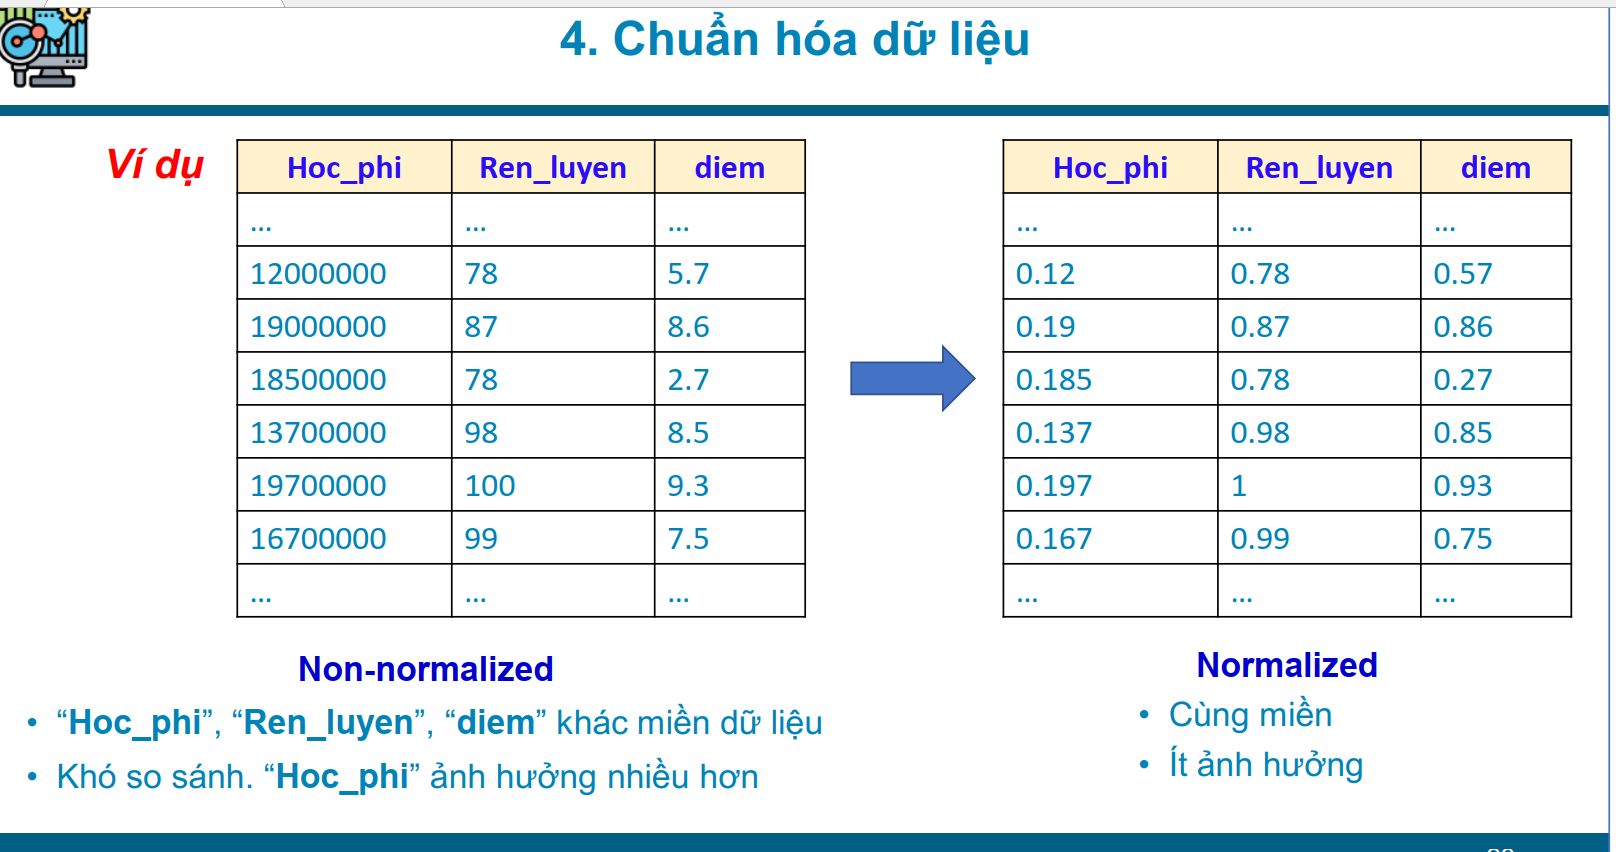


đưa giá trị về cùng miền, 1 kiểu để phân tích


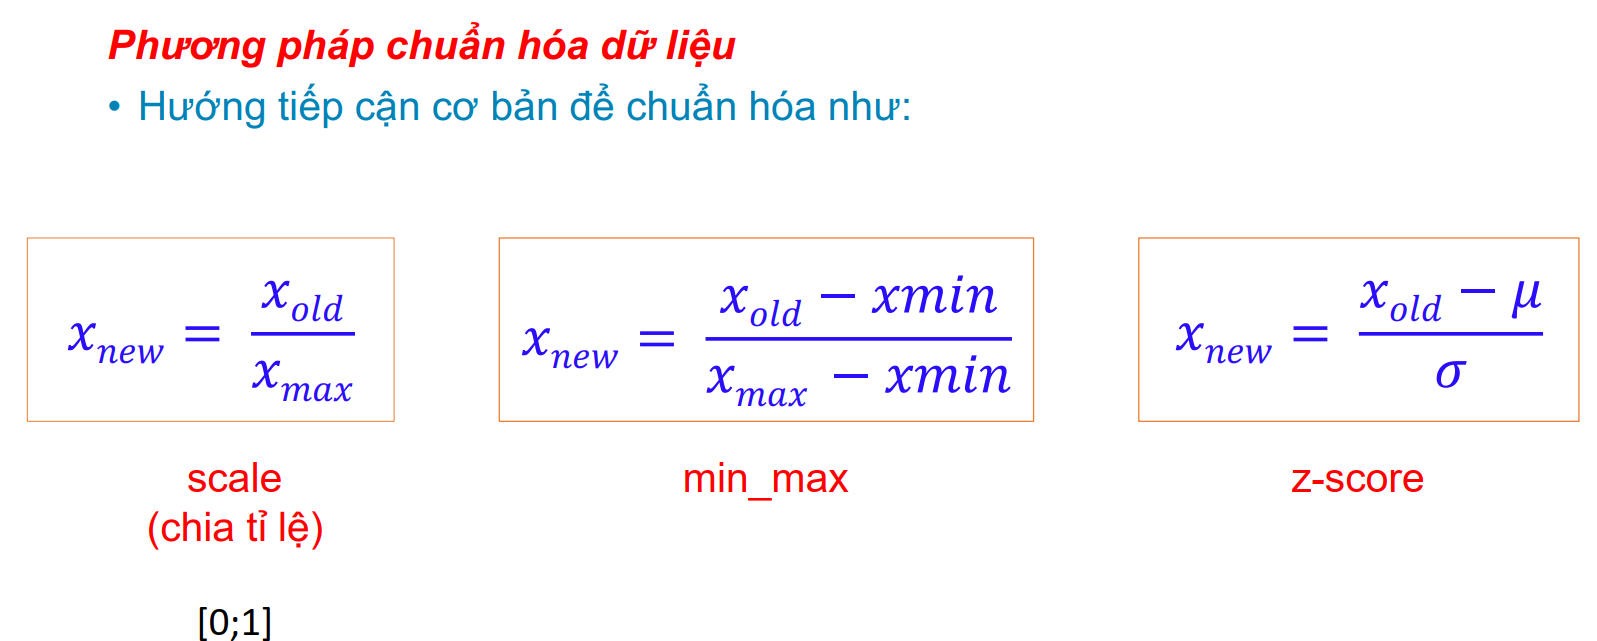

#### Scale chia tỉ lệ

ví dụ lấy cột price: giá trị nhỏ nhất là 5118, giá trị lớn nhất là 45400 = 5118/45400 = 0.11

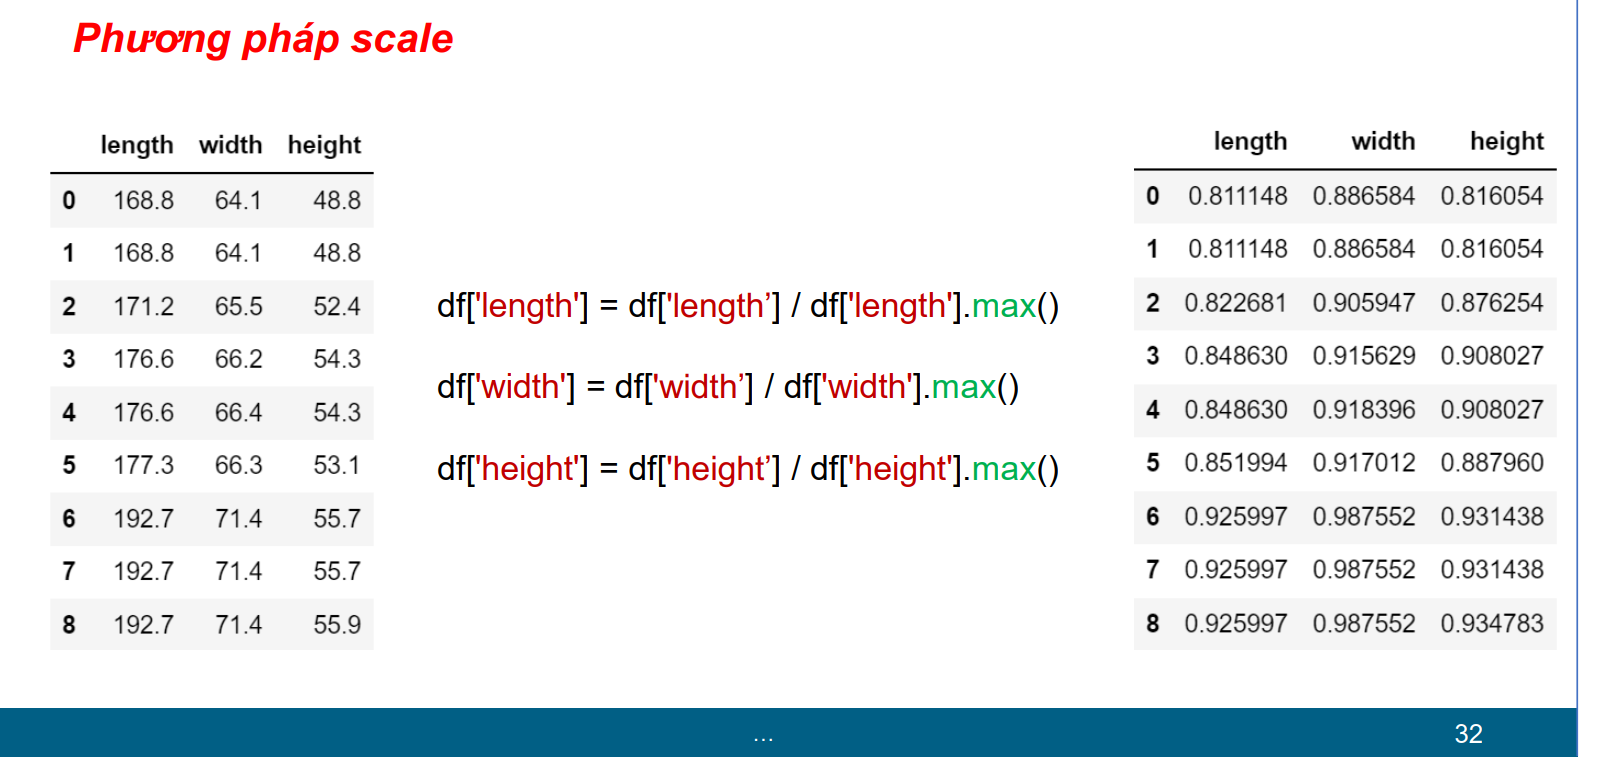

#### Dùng Min max
## Công thức

$$x_{new} = \frac{x_{old} - x_{min}}{x_{max} - x_{min}}$$

## Giải thích đơn giản

Phương pháp này **kéo dữ liệu về khoảng [0, 1]**:
- Giá trị **nhỏ nhất** → **0**
- Giá trị **lớn nhất** → **1**
- Các giá trị còn lại → **nằm trong khoảng 0-1 theo tỉ lệ**


Cho cột **Tuổi** của 5 người: `[25, 30, 35, 40, 45]`

| Bước | Tính toán | Kết quả |
|------|-----------|---------|
| 1. Tìm min | `min = 25` | |
| 2. Tìm max | `max = 45` | |
| 3. Tính từng giá trị | `(25-25)/(45-25) = 0/20` | `0` |
| 4. Tính từng giá trị | `(30-25)/(45-25) = 5/20` | `0.25` |
| 5. Tính từng giá trị | `(35-25)/(45-25) = 10/20` | `0.5` |
| 6. Tính từng giá trị | `(40-25)/(45-25) = 15/20` | `0.75` |
| 7. Tính từng giá trị | `(45-25)/(45-25) = 20/20` | `1` |

**Kết quả:** `[0, 0.25, 0.5, 0.75, 1]`


            df['length'] = (df['length'] - df['length'].min()) / (df['length'].max() - df['length'].min())
            df['width'] = (df['width'] - df['width'].min()) / (df['width'].max() - df['width'].min())
            df['height'] = (df['height'] - df['height'].min()) / (df['height'].max() - df['height'].min())


```python
áp dụng

df = pd.DataFrame({'age': [25, 30, 35, 40, 45]})
df['age_minmax'] = (df['age'] - df['age'].min()) / (df['age'].max() - df['age'].min())
print(df)
#    age  age_minmax
# 0   25        0.00
# 1   30        0.25
# 2   35        0.50
# 3   40        0.75
# 4   45        1.00


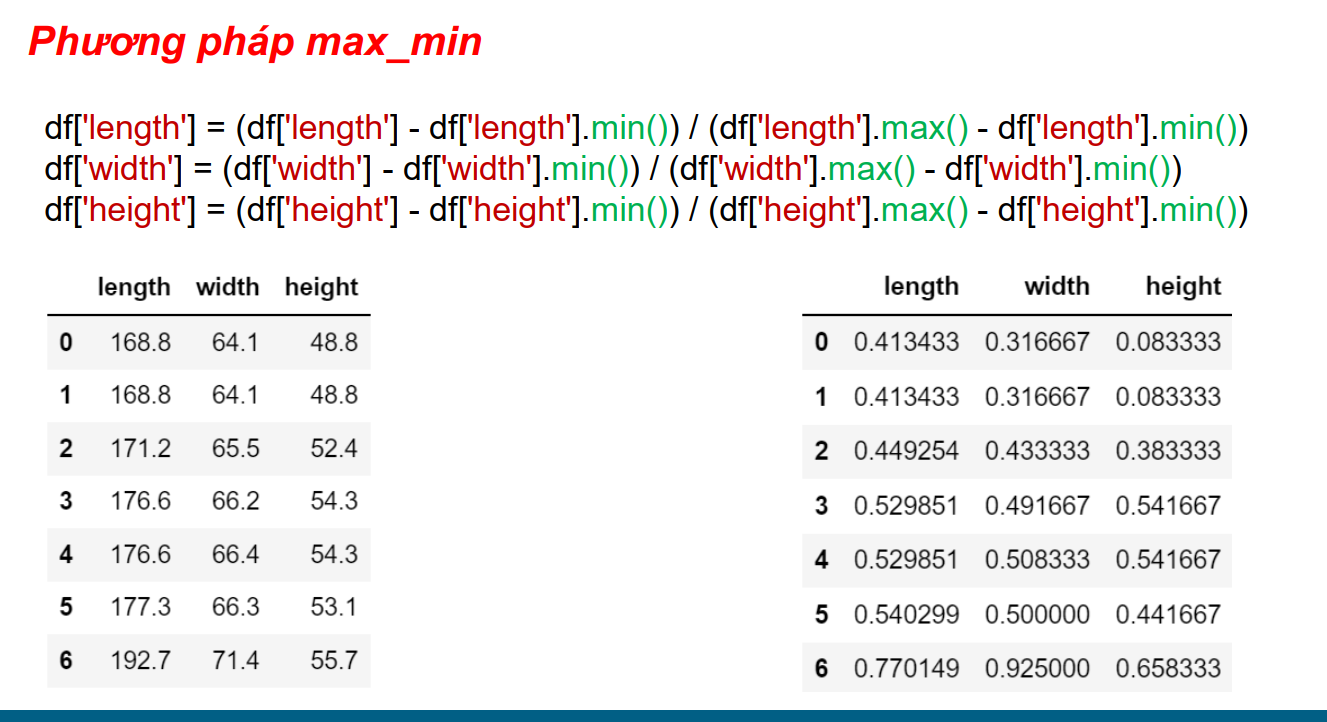

### Phương pháp max_min khác




In [52]:
from sklearn.preprocessing import MinMaxScaler

In [53]:
mm=MinMaxScaler() # kahi báo đối tượng

In [54]:
mm.fit_transform(df[['length']])

array([[0.41343284],
       [0.41343284],
       [0.44925373],
       [0.52985075],
       [0.52985075],
       [0.54029851],
       [0.77014925],
       [0.77014925],
       [0.77014925],
       [0.55373134],
       [0.53283582],
       [0.53283582],
       [0.53283582],
       [0.53283582],
       [0.71492537],
       [0.71492537],
       [0.78656716],
       [0.83432836],
       [0.        ],
       [0.22089552],
       [0.2641791 ],
       [0.24179104],
       [0.24179104],
       [0.24179104],
       [0.24179104],
       [0.24179104],
       [0.24179104],
       [0.24179104],
       [0.5       ],
       [0.47910448],
       [0.05223881],
       [0.05223881],
       [0.13283582],
       [0.13283582],
       [0.13283582],
       [0.33283582],
       [0.23880597],
       [0.39402985],
       [0.39402985],
       [0.5119403 ],
       [0.5119403 ],
       [0.5119403 ],
       [0.41791045],
       [0.44179104],
       [0.22089552],
       [0.22089552],
       [0.47014925],
       [0.873

# Chuẩn hóa dữ liệu bằng Z-score (Standardization)

## Công thức

$$
z=\frac{x-\mu}{\sigma}
$$

Trong đó:
- **x**: Giá trị ban đầu.
- **μ (mu)**: Giá trị trung bình của dữ liệu.
- **σ (sigma)**: Độ lệch chuẩn của dữ liệu.

## Ý nghĩa

- Đưa dữ liệu về chuẩn với:
  - Trung bình = **0**
  - Độ lệch chuẩn = **1**
- Giá trị sau chuẩn hóa có thể **âm, 0 hoặc dương** (không bị giới hạn trong khoảng [0,1]).
- Thường dùng cho các thuật toán như **KNN, SVM, Logistic Regression, PCA**.

## Ví dụ

Giả sử:
- Mean = **70** => tính trung bình của lớp tương đương với muy
- Standard Deviation = **10** => đô lệch chuẩn
- Một học sinh đạt **85 điểm**

Áp dụng công thức:

$$
z=\frac{85-70}{10}=1.5
$$

**Giải thích:** Điểm 85 cao hơn **1.5 độ lệch chuẩn** so với điểm trung bình của lớp.

## Khi nào sử dụng?

- Dữ liệu có các thuộc tính với đơn vị hoặc thang đo khác nhau.
- Muốn dữ liệu có trung bình bằng 0 và độ lệch chuẩn bằng 1.
- Phù hợp với các thuật toán học máy dựa trên khoảng cách hoặc giả định dữ liệu đã được chuẩn hóa.